<a href="https://colab.research.google.com/github/BajaniyaDEV/passscore/blob/password-scorer/Password_Scorer_labelled.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PassScore

PassScore trains a character-level language model on common passwords. The model learns what typical passwords look like, so it can score any new password: the more "normal" a password looks to the model, the more predictable (and weaker) it is.

The score is the password's surprise in bits: the sum of `-log2 p(next character)` over every character plus the end token.

The notebook follows the makemore series: bigram counts (part 1), an MLP (part 2), activation checks and init fixes (part 3), and a manual backprop check (part 4), then a live checker.

Cells are labelled `part.cell` (2.03 is part 2, cell 3) and each code cell starts with a comment saying what it does.

## Part 0: setup and data

Installs zxcvbn, loads the xato-net password list, cleans it and builds the character vocabulary. Same first steps as every makemore notebook, with passwords instead of names.

In [1]:
# ---- Cell 0.01: Install and import zxcvbn ----
# zxcvbn is Dropbox's well-known password strength checker. It's only used at the end (cell 5.01)
# as a second opinion next to the model's score. The ! runs pip from inside the notebook.
!pip install -q zxcvbn
from zxcvbn import zxcvbn

In [2]:
# ---- Cell 0.02: Load and clean the password list ----
# Downloads the xato-net list of 1,000,000 common passwords from SecLists on GitHub.
# Keeps passwords that are 4-30 characters long and only use the 94 printable keyboard characters
# (letters, digits, punctuation). makemore part 1 equivalent: words = open('names.txt')...
import torch, urllib.request, string, secrets, math, random
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/danielmiessler/SecLists/master/Passwords/Common-Credentials/xato-net-10-million-passwords-1000000.txt"
raw = urllib.request.urlopen(url).read().decode("utf-8", errors="ignore").splitlines()

chars = sorted(set(string.ascii_letters + string.digits + string.punctuation))  # 94 chars
allowed = set(chars)
words = [w for w in raw if 4 <= len(w) <= 30 and all(c in allowed for c in w)]

print(len(raw), "raw ->", len(words), "kept")
print(words[:15])

1000000 raw -> 999154 kept
['123456', 'password', '12345678', 'qwerty', '123456789', '12345', '1234', '111111', '1234567', 'dragon', '123123', 'baseball', 'abc123', 'football', 'monkey']


In [3]:
# ---- Cell 0.03: Vocabulary and first train/test split ----
# stoi/itos map each character to an integer and back. Index 0 ('\n') is the start/end token,
# doing the job of '.' in makemore (here '.' is a real password character, so it can't be used).
# V = 95 (94 characters + the token). Shuffles with seed 42 and splits 90% train / 10% test for the bigram model.
stoi = {c: i + 1 for i, c in enumerate(chars)}
stoi["\n"] = 0
itos = {i: c for c, i in stoi.items()}
V = len(stoi)   # 95

random.seed(42)
random.shuffle(words)
n = int(0.9 * len(words))
train, test = words[:n], words[n:]
print("vocab:", V, "| train:", len(train), "| test:", len(test))

vocab: 95 | train: 899238 | test: 99916


## Part 1: bigram model (makemore part 1)

Predicts each character from the one before it by counting pairs. Gives the first strength score and a baseline loss for the MLP to beat.

In [4]:
# ---- Cell 1.01: Count bigrams and build the probability matrix ----
# pairs() wraps each password in start/end tokens and returns (current char, next char) index pairs.
# bincount counts all pairs at once into the V x V matrix N (makemore's N[ix1, ix2] += 1 loop, but fast).
# +1 smoothing so no pair has zero probability, then each row is normalised so it sums to 1.
def pairs(ws):
    ix1, ix2 = [], []
    for w in ws:
        seq = [0] + [stoi[c] for c in w] + [0]
        ix1 += seq[:-1]
        ix2 += seq[1:]
    return torch.tensor(ix1), torch.tensor(ix2)

a, b = pairs(train)
N = torch.bincount(a * V + b, minlength=V * V).view(V, V)

P = (N + 1).float()               # +1 smoothing so nothing has zero probability
P /= P.sum(1, keepdim=True)

In [5]:
# ---- Cell 1.02: Test loss vs a uniform guess ----
# Average negative log likelihood of the real next characters in the test set.
# A uniform guess over 95 characters scores log(95) = 4.55; the bigram model gets about 3.06.
ta, tb = pairs(test)
test_nll = -torch.log(P[ta, tb]).mean().item()
print(f"uniform guess loss: {math.log(V):.3f}")
print(f"bigram test loss:   {test_nll:.3f}")

uniform guess loss: 4.554
bigram test loss:   3.061


In [6]:
# ---- Cell 1.03: Password strength score in bits (bigram) ----
# strength_bits adds up -log P(next char | current char) over the whole password, including the end token,
# and divides by log(2) to convert nats to bits. Predictable passwords get low scores.
# random_pw makes truly random passwords with secrets, which should score high.
# The tests list defined here is reused in cell 3.03 to compare against the MLP.
def strength_bits(pw):
    seq = [0] + [stoi[c] for c in pw if c in stoi] + [0]
    nll = -sum(math.log(P[x, y].item()) for x, y in zip(seq, seq[1:]))
    return nll / math.log(2)

def random_pw(k=12):
    return "".join(secrets.choice(chars) for _ in range(k))

tests = ["password", "password123", "iloveyou", "qwerty2024",
         "Tr0ub4dor&3", "correcthorsebatterystaple", random_pw(), random_pw()]
for pw in tests:
    print(f"{pw:28s} {strength_bits(pw):6.1f} bits")

password                       37.4 bits
password123                    46.9 bits
iloveyou                       39.2 bits
qwerty2024                     44.2 bits
Tr0ub4dor&3                    82.2 bits
correcthorsebatterystaple     107.1 bits
Dpx^[.*xV.n5                  105.6 bits
bN\;ZyE80*_-                  108.8 bits


In [7]:
# ---- Cell 1.04: Generate fake passwords (bigram) ----
# Starts at the start token, samples the next character from that row of P, and stops at the end token.
# Same sampling loop as makemore part 1. The output looks password-ish but has no memory beyond one character.
g = torch.Generator().manual_seed(2147483647)
for _ in range(15):
    out, ix = [], 0
    while True:
        ix = torch.multinomial(P[ix], 1, generator=g).item()
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

s119
zeillaxxBiand
1007wan
30kaquchur6
ae
JAartet6
14f3544
vveror5
xho5569945
gthgmugic
luekt531
10090677aas
x43
ahamer19281
guog3df


## Part 2: MLP (makemore part 2, with the part 3 initialisation fixes)

Looks at the previous 3 characters, gives each character a learned embedding, and uses a hidden layer to predict the next one.

In [8]:
# ---- Cell 2.01: New train / dev / test split ----
# Shuffles again and splits 80% train / 10% dev / 10% test, the makemore part 2 setup.
# Note: words was already shuffled in cell 0.03, so this is a different split from the bigram one.
# The bigram matrix P was built on the old 90% split, so some of these new dev/test passwords were in its training data.
# This only matters if you compare bigram and MLP losses directly; the bits comparison in 3.03 is fine as a rough guide.
random.seed(42)
random.shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
train, dev, test = words[:n1], words[n1:n2], words[n2:]
print("vocab:", V, "| train:", len(train), "| dev:", len(dev), "| test:", len(test))

vocab: 95 | train: 799323 | dev: 99915 | test: 99916


In [9]:
# ---- Cell 2.02: Build the context dataset ----
# block_size = 3: the previous 3 characters (padded with start tokens) predict the next one.
# Each password becomes one (context, next char) row per character plus one for the end token.
# Uses the first 200k train passwords and 20k dev/test passwords to keep training time reasonable.
import torch.nn.functional as F

block_size = 3   # context length: how many characters predict the next one (same as the video)

def build_dataset(ws):
    X, Y = [], []
    for w in ws:
        context = [0] * block_size
        for ch in w + "\n":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]   # crop and append
    return torch.tensor(X), torch.tensor(Y)

Xtr,  Ytr  = build_dataset(train[:200000])
Xdev, Ydev = build_dataset(dev[:20000])
Xte,  Yte  = build_dataset(test[:20000])
print(Xtr.shape, Xdev.shape, Xte.shape)

torch.Size([1712411, 3]) torch.Size([171204, 3]) torch.Size([170973, 3])


In [10]:
# ---- Cell 2.03: Initialise the network ----
# C: 10-number embedding per character. W1/b1: 200-neuron tanh hidden layer. W2/b2: output layer over 95 characters.
# FIX_INIT applies the makemore part 3 fixes: W2 and b2 near 0 so the starting loss is about log(95) instead of
# being confidently wrong, and W1 scaled by 0.2 so tanh doesn't saturate. Moves to GPU if one is available.
device = "cuda" if torch.cuda.is_available() else "cpu"

n_embd = 10      # size of each character's embedding vector
n_hidden = 200   # neurons in the hidden layer
FIX_INIT = True  # CHANGED: Now True to fix initialization issues

g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((V, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, V), generator=g)
b2 = torch.randn(V, generator=g)

if FIX_INIT:
    W1 *= 0.2    # fix 2: pre-activations closer to 0, so tanh stops saturating
    b1 *= 0.01   # small, not zero: a little variety between neurons
    W2 *= 0.01   # fix 1: logits near 0, so no confident wrong answers
    b2 *= 0      # output bias exactly 0

parameters = [p.to(device) for p in (C, W1, b1, W2, b2)]
C, W1, b1, W2, b2 = parameters
for p in parameters:
    p.requires_grad = True
print(sum(p.nelement() for p in parameters), "parameters")

26245 parameters


In [11]:
# ---- Cell 2.04: Training loop ----
# Minibatches of 32: forward pass (embed -> concat -> tanh hidden layer -> logits), cross-entropy loss,
# backward pass, then update. Learning rate 0.1, dropping to 0.01 after 150k steps. Log10 loss saved for plotting.
# CHECK_INIT = True stops after the first step so cell 3.01 can inspect the untrained network.
max_steps = 200000
batch_size = 32
CHECK_INIT = False   # CHANGED: Now False to run the full training loop

Xtr_d, Ytr_d = Xtr.to(device), Ytr.to(device)
lossi = []

for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, Xtr_d.shape[0], (batch_size,), device=device)
    Xb, Yb = Xtr_d[ix], Ytr_d[ix]

    # forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

    if CHECK_INIT:
        break

      0/ 200000: 4.5694
  10000/ 200000: 3.0082
  20000/ 200000: 3.4156
  30000/ 200000: 3.4249
  40000/ 200000: 2.7375
  50000/ 200000: 2.9330
  60000/ 200000: 3.1940
  70000/ 200000: 2.7227
  80000/ 200000: 2.9375
  90000/ 200000: 3.2884
 100000/ 200000: 2.8632
 110000/ 200000: 2.7903
 120000/ 200000: 2.7328
 130000/ 200000: 3.1672
 140000/ 200000: 2.7657
 150000/ 200000: 2.5177
 160000/ 200000: 2.6478
 170000/ 200000: 2.8586
 180000/ 200000: 2.8001
 190000/ 200000: 3.0232


## Part 3: activations and evaluation (makemore part 3)

Looks inside the hidden layer for saturated or dead neurons, then measures the trained model's loss.

loss at init: 2.82   expected: 4.55
first row of logits: [8.228808403015137, -1.9943656921386719, -4.4900641441345215, -3.170029878616333, -4.092455863952637, -4.3542866706848145, -3.737173557281494, -3.739100694656372]


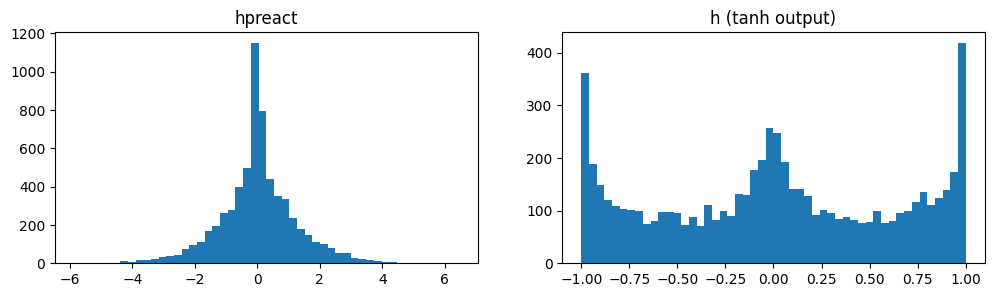

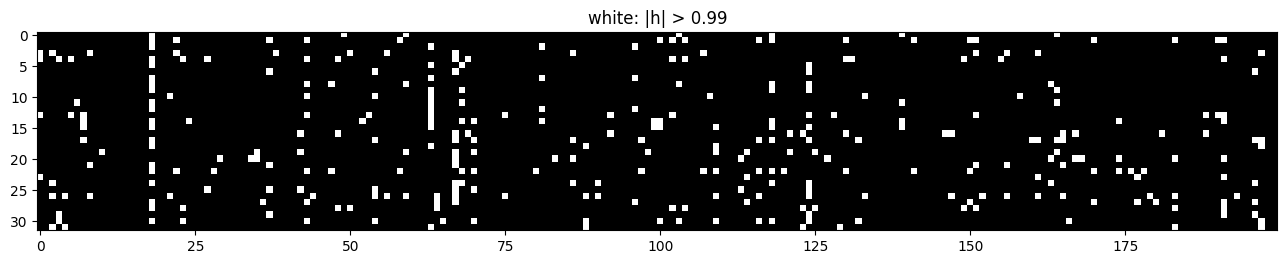

saturated: 5%   dead neurons: 0


In [12]:
# ---- Cell 3.01: Inside the network: loss, logits and tanh saturation ----
# Prints the loss next to the expected loss at init (log 95 = 4.55) and the first few logits.
# Histograms of hpreact (before tanh) and h (after tanh): values piled up at -1 and 1 mean saturated neurons.
# The white/black image shows |h| > 0.99 per example and neuron; a fully white column is a dead neuron.
# Note: with CHECK_INIT = False these variables come from the LAST training batch, so the saved output
# (loss 2.61) is the trained network, not the network at init. Set CHECK_INIT = True and re-run 2.03-2.04 to see init.
print(f"loss at init: {loss.item():.2f}   expected: {-torch.tensor(1 / V).log().item():.2f}")
print("first row of logits:", logits[0, :8].tolist())

# histograms: are the pre-activations too wide? are the tanh outputs stuck at -1 and 1?
plt.figure(figsize=(12, 3))
plt.subplot(121); plt.hist(hpreact.view(-1).tolist(), 50); plt.title("hpreact")
plt.subplot(122); plt.hist(h.view(-1).tolist(), 50); plt.title("h (tanh output)")
plt.show()

# white = saturated neuron for that example; a fully white column = dead neuron
sat = (h.abs() > 0.99)
plt.figure(figsize=(16, 4))
plt.imshow(sat.cpu(), cmap="gray", interpolation="nearest")
plt.title("white: |h| > 0.99"); plt.show()

print(f"saturated: {sat.float().mean().item():.0%}   dead neurons: {sat.all(0).sum().item()}")

train 2.8531
dev 2.8594


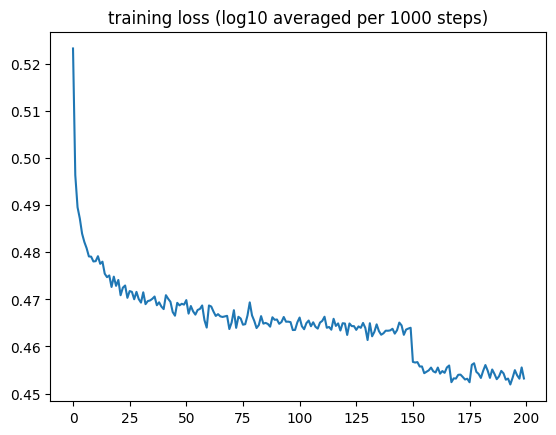

In [13]:
# ---- Cell 3.02: Evaluate train/dev loss and plot training ----
# split_loss runs a whole split through the model with gradients off. Train and dev are close (about 2.85 / 2.86),
# so there's little overfitting. The plot averages the log10 loss over blocks of 1000 steps to smooth out batch noise.
@torch.no_grad()
def split_loss(split):
    x, y = {"train": (Xtr, Ytr), "dev": (Xdev, Ydev), "test": (Xte, Yte)}[split]
    x, y = x.to(device), y.to(device)
    emb = C[x]
    h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, round(loss.item(), 4))

split_loss("train")
split_loss("dev")

if len(lossi) >= 1000:
    plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
    plt.title("training loss (log10 averaged per 1000 steps)")
else:
    plt.plot(lossi)
    plt.title("training loss (log10)")
plt.show()

In [14]:
# ---- Cell 3.03: Generate fake passwords and score with the MLP ----
# First half: samples 15 new passwords from the MLP, sliding the 3-character context window (makemore part 2 sampling).
# Second half: mlp_bits scores a password the same way as strength_bits, but with the MLP's probabilities.
# Prints bigram vs MLP bits for the tests list. Common passwords drop a lot (password: 37.4 -> 26.5)
# because the MLP recognises longer patterns; random passwords stay high.
g = torch.Generator().manual_seed(2147483647 + 10)
for _ in range(15):
    out, context = [], [0] * block_size
    while len(out) < 40:
        with torch.no_grad():
            emb = C[torch.tensor([context], device=device)]
            h = torch.tanh(emb.view(1, -1) @ W1 + b1)
            probs = F.softmax(h @ W2 + b2, dim=1).cpu()
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        if ix == 0:
            break
        out.append(itos[ix])
    print("".join(out))

@torch.no_grad()
def mlp_bits(pw):
    pw = "".join(c for c in pw if c in stoi and c != "\n")
    x, y = build_dataset([pw])
    x, y = x.to(device), y.to(device)
    h = torch.tanh(C[x].view(x.shape[0], -1) @ W1 + b1)
    nll = F.cross_entropy(h @ W2 + b2, y, reduction="sum").item()
    return nll / math.log(2)

for pw in tests:   # the list from cell 5
    print(f"{pw:28s} bigram {strength_bits(pw):6.1f}   MLP {mlp_bits(pw):6.1f} bits")

hilan85
smirassan
kcranenhri
kse
vxx
fupfybowo126w3310
112121383
jabek1
691777672t
foothele68
lunce50fore
370378
zan
wphz
dee
password                     bigram   37.4   MLP   28.2 bits
password123                  bigram   46.9   MLP   34.0 bits
iloveyou                     bigram   39.2   MLP   30.8 bits
qwerty2024                   bigram   44.2   MLP   36.9 bits
Tr0ub4dor&3                  bigram   82.2   MLP   89.1 bits
correcthorsebatterystaple    bigram  107.1   MLP  102.2 bits
Dpx^[.*xV.n5                 bigram  105.6   MLP  116.2 bits
bN\;ZyE80*_-                 bigram  108.8   MLP  128.2 bits


## Part 4: manual backprop check (makemore part 4)

Recomputes the gradients of the loss by hand and checks them against PyTorch's autograd.

In [15]:
# ---- Cell 4.01: Backprop through the softmax by hand ----
# cmp() compares a hand-computed gradient with the one autograd stored in .grad.
# Takes one batch, splits the forward pass into small steps (subtract max, exp, sum, invert, multiply, log, pick).
# retain_grad keeps autograd's gradients for those middle tensors, then each gradient is derived manually
# from logprobs back to norm_logits. Every row should print exact: True.
def cmp(s, dt, t):
    ex = torch.all(dt == t.grad).item()
    app = torch.allclose(dt, t.grad)
    maxdiff = (dt - t.grad).abs().max().item()
    print(f"{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}")

n = batch_size
ix = torch.randint(0, Xtr.shape[0], (n,))
Xb, Yb = Xtr[ix].to(device), Ytr[ix].to(device)
rows = torch.arange(n, device=device)

# forward pass, broken into small pieces
emb = C[Xb]
h = torch.tanh(emb.view(n, -1) @ W1 + b1)
logits = h @ W2 + b2
logit_maxes = logits.max(1, keepdim=True).values
norm_logits = logits - logit_maxes          # subtract the max for numerical safety
counts = norm_logits.exp()
counts_sum = counts.sum(1, keepdim=True)
counts_sum_inv = counts_sum ** -1           # ** -1 instead of 1/x, as in the video
probs = counts * counts_sum_inv
logprobs = probs.log()
loss = -logprobs[rows, Yb].mean()

for p in parameters:
    p.grad = None
for t in [logprobs, probs, counts_sum_inv, counts_sum, counts, norm_logits]:
    t.retain_grad()
loss.backward()

# manual backward pass
dlogprobs = torch.zeros_like(logprobs)
dlogprobs[rows, Yb] = -1.0 / n                         # only the plucked-out entries matter
dprobs = (1.0 / probs) * dlogprobs                     # d/dx log(x) = 1/x
dcounts_sum_inv = (counts * dprobs).sum(1, keepdim=True)  # broadcast backwards = sum
dcounts = counts_sum_inv * dprobs
dcounts_sum = (-counts_sum ** -2) * dcounts_sum_inv
dcounts += torch.ones_like(counts) * dcounts_sum       # counts is used twice: gradients add up
dnorm_logits = counts * dcounts                        # d/dx e^x = e^x

cmp("logprobs", dlogprobs, logprobs)
cmp("probs", dprobs, probs)
cmp("counts_sum_inv", dcounts_sum_inv, counts_sum_inv)
cmp("counts_sum", dcounts_sum, counts_sum)
cmp("counts", dcounts, counts)
cmp("norm_logits", dnorm_logits, norm_logits)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0


## Part 5: live strength checker

A password box that scores what you type with the MLP and shows zxcvbn's score next to it.

In [16]:
# ---- Cell 5.01: Interactive password box ----
# widgets.Password hides what you type. On every change it scores the password with mlp_bits and labels it
# weak (< 30 bits), okay (< 50) or strong, plus zxcvbn's 0-4 score for comparison.
# The google.colab lines are needed in Colab only; delete those two lines to run it in Jupyter or VS Code.
import ipywidgets as widgets
from IPython.display import display
from google.colab import output
output.enable_custom_widget_manager()

box = widgets.Password(placeholder="type a password")
out = widgets.Output()

def on_change(change):
    pw = change["new"]
    out.clear_output()
    with out:
        if not pw:
            return
        bits = mlp_bits(pw)
        label = "weak" if bits < 30 else "okay" if bits < 50 else "strong"
        print(f"{bits:.1f} bits -> {label}   (zxcvbn: {zxcvbn(pw)['score']}/4)")

box.observe(on_change, names="value")
display(box, out)

Password(placeholder='type a password')

Output()